# 07 — Niveau de confiance et valeur de repli

**Objectif :** produire une carte de Q10 qui n'utilise le modèle **que là où nos données le justifient**, et qui revient ailleurs à la valeur actuelle d'ORCHIDEE, **Q10 = 2.0**.

**La règle étudiée :** chaque cellule $x$ reçoit une confiance $c(x)$ entre 0 et 1, calculée à partir de $n_r(x)$, le nombre de sites mesurés à moins de $r$ km :
- **seuil** : $c(x) = 1$ si $n_r(x) \geq n^*$, sinon $c(x) = 0$ ;
- **mélange** : $c(x) = \min\big(1,\ n_r(x)/n^*\big)$, qui monte progressivement de 0 (aucun site) à 1 ($n^*$ sites ou plus).

Puis :

$$\log Q_{10}(x) = c(x)\,\log \hat{f}(x) + \big(1 - c(x)\big)\,\log 2.0,$$

où $\hat{f}$ est le modèle. Le mélange se fait en log, comme l'apprentissage du modèle ; avec $c = 0$, on retrouve exactement 2.0.

**Ce qui est fixé, et pourquoi :**

| Élément | Valeur | Justification |
|---|---|---|
| Valeur de repli | 2.0 | décision de l'équipe : c'est la valeur actuelle d'ORCHIDEE. Là où nos données ne disent rien, on ne change rien. |
| Modèle $\hat{f}$ | Elastic Net V2 bridé | proposition de 04 (partie C), pas encore validée. La partie B (étape 3) vérifie que le résultat n'en dépend pas. |
| Protocole | validation croisée spatiale commune | `src/protocole.py` : zones de 10°, 5 plis × 20 répétitions, mêmes plis que 04. |

**Ce que les données choisissent, sans valeur fixée à l'avance :** le rayon $r$, le nombre de sites $n^*$, la forme de la règle (seuil ou mélange), et la perte qui sert à les choisir. Chaque valeur vient d'une **recherche sur grille** : on teste toutes les valeurs d'une grille large, on retient celle qui minimise la perte, puis on vérifie que ce minimum est **robuste** (répétitions, modèles, quantité de données, validation croisée imbriquée) et **cohérent avec l'usage dans ORCHIDEE**.

**Plan :**
- **Partie A** — Le gain du modèle dépend-il du nombre de sites voisins ?
- **Partie B** — Recherche sur grille : surfaces de perte, stabilité de l'optimum, choix de la perte.
- **Partie C** — Seuil ou mélange : critères propres à la carte et à ORCHIDEE.
- **Partie D** — Robustesse du réglage retenu : profils autour de l'optimum, quantité de données, validation croisée imbriquée.
- **Partie E** — Carte mondiale et aire d'applicabilité.

Chaque étape suit la structure : **Objectif** → **Raisonnement** → code → **Constat**.

Prérequis : le cache des prédictions de `04_comparaison_modeles` (`resultats/04/`). Les calculs propres à ce notebook sont mis en cache dans `resultats/07/`.

In [1]:
# Imports : calcul, tableaux, graphiques, protocole commun et modèles (dossier src/)
import sys
sys.path.append("..")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.protocole import decoupages_spatiaux, evaluer, evaluer_en_cache, comparer, Q10_REFERENCE
from src import modeles as M

In [2]:
# Masquer les avertissements de convergence des modèles, sans effet sur les résultats (comme dans 04)
import warnings
warnings.filterwarnings("ignore")

In [3]:
# Table de modélisation (cf. 02, partie B, étape 4) et Q10 observés sous forme de tableau
v4 = pd.read_csv("../data/dataset_v4.csv")
q = v4.Q10.values

In [4]:
# Découpages de la validation croisée spatiale, identiques à ceux de 04
decoupages = decoupages_spatiaux(v4.bloc)

In [5]:
# Candidats (typologie en one-hot), comme dans 04
candidats = ["lat", "lon", "MAT_public", "logMAP", "pH_public", "logN515", "clay", "sand", "CN", "SWC_mean", "SWC_warm_rel"]
X = v4[candidats].join(pd.get_dummies(v4.typologie, dtype=float))

In [6]:
# Configuration étudiée : Elastic Net V2 bridé (cf. 04, partie C), sous la forme predire(tr, te) attendue par le protocole
predire_en = lambda tr, te: M.predire_v2(lambda p: M.elastic_net(), X, v4.log_Q10, v4.bloc, tr, te, brider=True)

In [7]:
# Prédictions hors échantillon sur les 100 plis : lues dans le cache de 04 (recalculées en ≈ 30 s si le cache n'existe pas)
scores_modele, oof = evaluer_en_cache("../resultats/04/Elastic_Net_V2_bride.pkl", predire_en, decoupages, v4.Q10)

In [8]:
# Références sur les mêmes plis : la valeur fixe 2.0 et la moyenne des Q10 d'entraînement
scores_deux = evaluer(lambda tr, te: np.full(len(te), Q10_REFERENCE), decoupages, v4.Q10)[0]
scores_moyenne = evaluer(lambda tr, te: np.full(len(te), q[tr].mean()), decoupages, v4.Q10)[0]

In [9]:
# Fonction : distance sur la sphère (km) entre des points donnés en degrés (formule de haversine)
def distance_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    return 6371 * 2 * np.arcsin(np.sqrt(np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2))

In [10]:
# Distances entre tous les sites (tableau 131 × 131)
D = distance_km(v4.lat.values[:, None], v4.lon.values[:, None], v4.lat.values, v4.lon.values)

In [11]:
# Pour chaque pli : distances de chaque site de test à chaque site d'entraînement, les seuls sites « connus » du modèle
distances = [D[np.ix_(te, tr)] for _, tr, te in decoupages]

## Partie A — Le gain du modèle dépend-il du nombre de sites voisins ?

**Objectif :** vérifier l'hypothèse sur laquelle repose toute la méthode : le modèle prédit mieux là où il connaît des sites proches, et ne fait pas mieux qu'une constante là où il n'en connaît aucun.

**Raisonnement :**
- Pour chaque site de test, on compte les sites **d'entraînement du même pli** à moins de $r$ km. C'est la situation de la carte : une cellule ne « connaît » que les sites ayant servi à l'entraînement. Compter aussi les sites de test serait une fuite.
- On compare, selon ce nombre de voisins, l'erreur du modèle à celle de **2.0** et à celle de la **moyenne d'entraînement**.
- **Pourquoi aussi la moyenne ?** Nos sites ont un Q10 moyen élevé (2.51). Battre 2.0 peut venir de ce seul niveau, qui ne vaut que pour nos régions (cf. 04, partie A). La moyenne a le même niveau que le modèle : la battre montre que le modèle apporte une **information locale**.
- Trois rayons (500, 1 000 et 2 000 km), **à titre d'illustration seulement** : le choix du rayon se fait dans la partie B.
- Barres d'erreur : écart-type du gain entre les 20 répétitions (chaque répétition teste les 131 sites une fois).

In [12]:
# Cas de test : une ligne par site de test et par répétition (Q10 observé, prédiction du modèle, moyenne d'entraînement)
cas = pd.DataFrame([{"repetition": s, "Q10": q[k], "modele": oof[s, k], "moyenne": q[tr].mean()} for s, tr, te in decoupages for k in te])

In [13]:
# Nombre de sites d'entraînement à moins de 500, 1 000 et 2 000 km de chaque cas de test (même ordre que la table)
for r in [500, 1000, 2000]:
    cas[f"voisins {r}"] = np.concatenate([(d < r).sum(axis=1) for d in distances])

In [14]:
# Erreurs quadratiques du modèle, de la valeur fixe 2.0 et de la moyenne d'entraînement
cas["e modèle"], cas["e 2.0"], cas["e moyenne"] = (cas.Q10 - cas.modele) ** 2, (cas.Q10 - Q10_REFERENCE) ** 2, (cas.Q10 - cas.moyenne) ** 2

In [15]:
# Fonction : classe de nombre de voisins
classes = lambda n: pd.cut(n, [-1, 0, 1, 2, 4, 9, 19, np.inf], labels=["0", "1", "2", "3–4", "5–9", "10–19", "20+"])

In [16]:
# Part des cas de test (%) dans chaque classe de voisins, pour chaque rayon
pd.DataFrame({f"r = {r} km": classes(cas[f"voisins {r}"]).value_counts(normalize=True, sort=False).mul(100) for r in [500, 1000, 2000]}).round(1)

,r = 500 km,r = 1000 km,r = 2000 km
0,49.0,9.5,1.0
1,12.6,4.6,0.3
2,6.5,12.3,1.0
3–4,18.0,17.9,6.2
5–9,12.2,20.5,8.0
10–19,1.7,31.3,16.2
20+,0.0,3.9,67.3


In [17]:
# Fonction : gain de RMSE du modèle (%) sur une référence, par classe de voisins (une ligne par répétition)
def gain_par_classe(r, reference):
    rmse = cas.groupby(["repetition", classes(cas[f"voisins {r}"])], observed=True)[["e modèle", f"e {reference}"]].mean() ** 0.5
    return (100 * (1 - rmse["e modèle"] / rmse[f"e {reference}"])).unstack()

In [18]:
# Gain moyen du modèle (%) par classe de voisins, pour chaque rayon et chaque référence (moyenne des 20 répétitions)
pd.DataFrame({(f"r = {r} km", f"vs {ref}"): gain_par_classe(r, ref).mean() for r in [500, 1000, 2000] for ref in ["2.0", "moyenne"]}).round(1)

r = 500 km            r = 1000 km            r = 2000 km           
          vs 2.0 vs moyenne      vs 2.0 vs moyenne      vs 2.0 vs moyenne
0           15.7        4.7        -0.8      -10.8       -68.4       26.2
1           -4.4       -0.3         1.1       -5.2        24.3       20.9
2            8.4       21.9        10.5       12.4        -3.8      -15.5
3–4          1.6       -5.0        20.7       10.5        -0.6       -1.5
5–9         11.9       -6.7        14.0        6.5         0.6        4.1
10–19       15.5      -50.2        10.9        4.1        20.6        6.7
20+          NaN        NaN        36.7        8.5        14.6        2.0

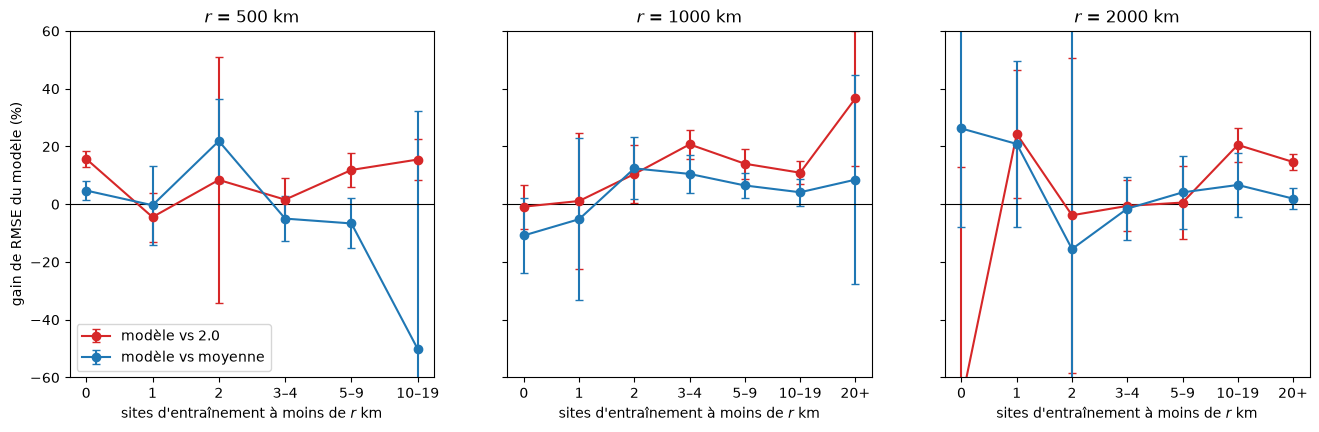

In [19]:
# Graphique : gain du modèle selon le nombre de sites d'entraînement à moins de r km (moyenne ± écart-type sur les 20 répétitions)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, r in zip(axes, [500, 1000, 2000]):
    for reference, couleur in [("2.0", "tab:red"), ("moyenne", "tab:blue")]:
        g = gain_par_classe(r, reference)
        ax.errorbar(g.columns.astype(str), g.mean(), yerr=g.std(), marker="o", capsize=3, color=couleur, label=f"modèle vs {reference}")
    ax.axhline(0, color="k", lw=0.8); ax.set_title(f"$r$ = {r} km"); ax.set_xlabel("sites d'entraînement à moins de $r$ km")
axes[0].set_ylabel("gain de RMSE du modèle (%)"); axes[0].set_ylim(-60, 60); axes[0].legend()
plt.show()

**Constat :**
- **À $r = 1\,000$ km, l'hypothèse est vérifiée.** Sans voisin, le modèle ne fait pas mieux que 2.0 (−0.8 %) et fait nettement moins bien que la moyenne (−10.8 %). Avec un seul voisin, c'est à peine mieux (+1.1 % et −5.2 %). **À partir de deux voisins, le modèle bat les deux références** : +10.5 à +36.7 % contre 2.0 et +4.1 à +12.4 % contre la moyenne. Le gain sur la moyenne, c'est-à-dire l'information locale, devient positif à 2 voisins et le reste dans toutes les classes suivantes.
- **À $r = 500$ km, le rayon est trop petit.** La moitié des cas de test (49 %) n'ont aucun voisin, et pourtant le modèle y bat 2.0 (+15.7 %) et la moyenne (+4.7 %). Cette classe « sans voisin » mélange des sites vraiment isolés et des sites qui ont des voisins entre 500 et 1 000 km, porteurs d'information. Les courbes n'ont pas de tendance claire.
- **À $r = 2\,000$ km, le rayon est trop grand.** 67 % des cas ont plus de 20 voisins, et les classes de 0 à 2 voisins ne regroupent que 2.3 % des cas : le rayon ne distingue plus les sites isolés des autres.
- **Le rayon compte donc autant que le nombre de sites.** Il faut les choisir ensemble, sur une grille (partie B).

## Partie B — Recherche sur grille

### Étape 1 — La perte, la grille et le calcul

**Objectif :** fixer ce qu'on minimise et l'ensemble des valeurs testées, avant de regarder où se trouve le minimum.

**Raisonnement :**
- **Perte** : RMSE de la règle (sur l'échelle de Q10), moyennée sur les 100 plis de la validation croisée spatiale, comme pour le choix des modèles (04). Pour chaque site de test, la confiance est calculée avec les seuls sites d'entraînement de son pli.
- **Deux versions de la perte**, selon la valeur de repli utilisée **pendant l'évaluation** :
  - **repli = 2.0** : la règle exactement telle qu'elle sera appliquée sur la carte ;
  - **repli = moyenne d'entraînement** : une constante de même niveau que le modèle. Cette perte ne récompense le modèle que là où il apporte une information locale, et pas pour le niveau moyen de nos sites (partie A).

  On calcule les deux ; le choix entre elles se fait à l'étape 4, sur des critères vérifiés. Sur la carte, la valeur de repli reste 2.0 dans tous les cas.
- **Grille** :
  - **$r$ de 100 à 3 000 km, par pas de 100 km.** 100 km, c'est environ deux cellules d'ORCHIDEE (0.5°). 3 000 km, c'est deux fois la portée maximale du semi-variogramme (≈ 1 500 km, cf. 02) : au-delà, les sites ne se ressemblent plus du tout.
  - **$n^*$ de 1 à 30.** La valeur la plus prudente (1) est incluse, et la borne haute dépasse largement les densités de sites les plus fréquentes (cf. partie A).
  - **Les deux formes** (seuil et mélange). En tout, $30 \times 30 \times 2 = 1\,800$ règles, chacune évaluée avec les deux pertes.
- **Contrôle de la grille** : l'optimum ne doit pas tomber sur un bord de la grille. Sinon, la grille serait trop étroite.

In [20]:
# Grille testée : rayons (km), nombres de sites et formes de la règle
RAYONS, NOMBRES, FORMES = np.arange(100, 3001, 100), np.arange(1, 31), ["seuil", "mélange"]

In [21]:
# Valeur de repli utilisée pendant l'évaluation : la valeur fixe 2.0, ou la moyenne des Q10 d'entraînement du pli
REPLIS = {"2.0": lambda tr: Q10_REFERENCE, "moyenne": lambda tr: q[tr].mean()}

In [22]:
# Fonction : confiance à partir du nombre de voisins n (seuil ou mélange) ; n_etoile peut être un tableau (une ligne par valeur)
def confiance(n, n_etoile, forme):
    return (n >= n_etoile).astype(float) if forme == "seuil" else np.minimum(1, n / n_etoile)

In [23]:
# Fonction : Q10 de la règle, mélange en log du modèle et de la valeur de repli selon la confiance c
def regle(q_modele, q_repli, c):
    return np.exp(c * np.log(q_modele) + (1 - c) * np.log(q_repli))

In [24]:
# Fonction : RMSE de la règle sur un pli (s, tr, te), pour un rayon r et pour toutes les valeurs de n* de la grille à la fois
def rmse_pli(pli, d, oof, r, forme, repli):
    s, tr, te = pli
    c = confiance((d < r).sum(axis=1), NOMBRES[:, None], forme)  # une ligne par valeur de n*
    return np.sqrt(np.mean((q[te] - regle(oof[s, te], repli(tr), c)) ** 2, axis=1))

In [25]:
# Fonction : RMSE de chaque règle (r, n*) de la grille (lignes) sur chaque pli d'un découpage (colonnes)
def recherche_grille(oof, decoupages, distances, forme, repli):
    T = np.array([[rmse_pli(p, d, oof, r, forme, repli) for p, d in zip(decoupages, distances)] for r in RAYONS])  # rayons × plis × n*
    return pd.DataFrame(T.transpose(0, 2, 1).reshape(-1, len(decoupages)), index=pd.MultiIndex.from_product([RAYONS, NOMBRES], names=["r", "n*"]))

In [26]:
# Recherche sur grille : RMSE de chaque règle sur chaque pli, pour chaque perte et chaque forme
recherche = {(perte, forme): recherche_grille(oof, decoupages, distances, forme, REPLIS[perte]) for perte in REPLIS for forme in FORMES}

In [27]:
# Fonctions : optimum (r, n*) d'une recherche, et scores par pli d'une règle (au format attendu par comparer)
optimum_de = lambda resultats: resultats.mean(axis=1).idxmin()
scores_de = lambda resultats, rn: pd.DataFrame({"rmse": resultats.loc[rn].values})

### Étape 2 — Surfaces de perte, optimum et règles équivalentes

**Objectif :** localiser le minimum de chaque surface et mesurer à quel point il se distingue des autres règles.

**Raisonnement :**
- **Surface de perte** : RMSE moyenne selon $r$ (lignes) et $n^*$ (colonnes). L'**optimum** est la règle qui la minimise.
- **Règles équivalentes** : celles dont l'écart apparié avec l'optimum reste sous une erreur standard (Nadeau et Bengio), comme pour le choix des modèles (04, partie B). Plus cet ensemble est petit, plus les données désignent nettement l'optimum.
- **Références** : le modèle seul (confiance 1 partout) et la constante de repli seule (confiance 0 partout) sont deux cas limites de la règle. Une grande valeur de $r$ avec $n^* = 1$ se rapproche du premier, une petite valeur de $r$ du second.

In [28]:
# Fonction : pour chaque règle (r, n*), True si son écart apparié avec l'optimum reste sous une erreur standard
def equivalentes(resultats):
    meilleure = scores_de(resultats, optimum_de(resultats))
    ecarts = pd.DataFrame({rn: comparer(scores_de(resultats, rn), meilleure) for rn in resultats.index}).T
    return ecarts["écart"] <= ecarts["erreur standard"]

In [29]:
# Règles équivalentes à l'optimum, pour chaque surface
equivalence = {k: equivalentes(res) for k, res in recherche.items()}

In [30]:
# Pour chaque surface : optimum, sa RMSE, nombre de règles équivalentes (sur 900) ; pour mémoire, le modèle seul et les constantes
pd.DataFrame({f"repli {p}, {f}": {"r (km)": optimum_de(res)[0], "n*": optimum_de(res)[1], "RMSE": res.mean(axis=1).min(),
                                  "règles équivalentes": equivalence[(p, f)].sum()} for (p, f), res in recherche.items()}).T

,r (km),n*,RMSE,règles équivalentes
"repli 2.0, seuil",1400.0,3.0,0.940849,269.0
"repli 2.0, mélange",1100.0,3.0,0.943245,455.0
"repli moyenne, seuil",1000.0,2.0,0.918795,103.0
"repli moyenne, mélange",1000.0,3.0,0.922032,257.0


In [31]:
# RMSE des cas limites : modèle seul, valeur fixe 2.0 seule, moyenne d'entraînement seule
pd.Series({"modèle seul": scores_modele.rmse.mean(), "2.0 seul": scores_deux.rmse.mean(), "moyenne seule": scores_moyenne.rmse.mean()}).round(3)

modèle seul      0.950
2.0 seul         1.083
moyenne seule    0.980
dtype: float64

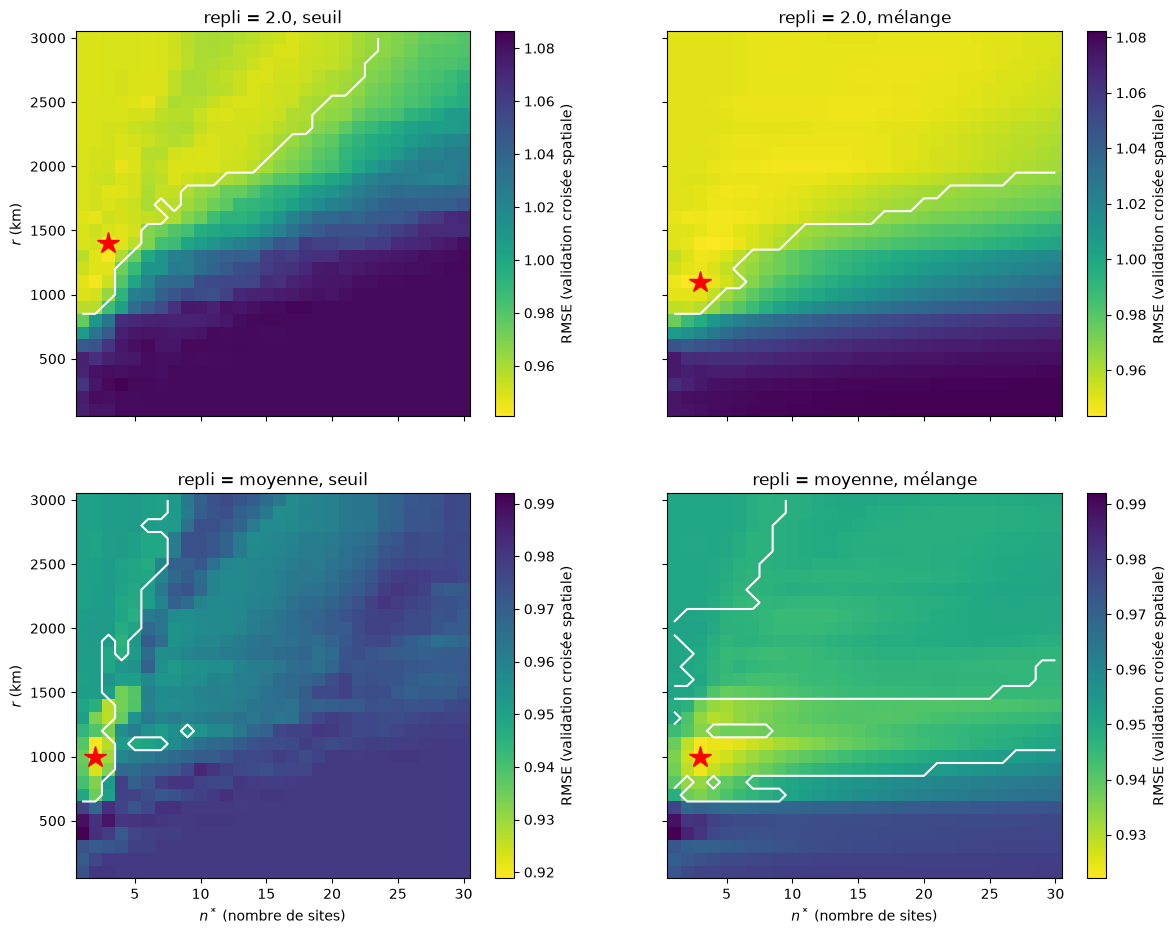

In [32]:
# Graphique : surfaces de perte ; étoile = optimum ; contour blanc = règles équivalentes à l'optimum
fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharex=True, sharey=True)
for ax, ((perte, forme), res) in zip(axes.flat, recherche.items()):
    surface = res.mean(axis=1).unstack()
    im = ax.imshow(surface, origin="lower", aspect="auto", extent=(0.5, 30.5, 50, 3050), cmap="viridis_r")
    ax.contour(NOMBRES, RAYONS, equivalence[(perte, forme)].unstack().astype(float), levels=[0.5], colors="w")
    r, n = optimum_de(res); ax.plot(n, r, "r*", ms=16)
    ax.set_title(f"repli = {perte}, {forme}"); fig.colorbar(im, ax=ax, label="RMSE (validation croisée spatiale)")
for ax in axes[1]: ax.set_xlabel("$n^*$ (nombre de sites)")
for ax in axes[:, 0]: ax.set_ylabel("$r$ (km)")
plt.show()

**Constat :**
- **Les quatre surfaces ont leur minimum au même endroit**, une « vallée » autour de $r \approx 1\,000$ km et de $n^*$ entre 2 et 3 : (1 400 km, 3) et (1 100 km, 3) avec repli sur 2.0 ; (1 000 km, 2) et (1 000 km, 3) avec repli sur la moyenne. **Aucun optimum n'est sur un bord de la grille** : la grille est assez large.
- **Forme de la surface.** Sous ≈ 700 km, la confiance est presque toujours nulle et la règle revient à la constante (RMSE ≈ 0.98 à 1.08). Pour un grand rayon et un petit $n^*$, la confiance vaut presque toujours 1 et la règle revient au modèle seul (≈ 0.95). Le minimum (0.919 à 0.943) est **plus bas que ces deux cas limites** : faire confiance au modèle seulement près des sites fait mieux que lui faire confiance partout, ou nulle part.
- **Mais l'optimum se distingue peu de ses voisins.** 103 à 455 règles sur 900 restent à moins d'une erreur standard de l'optimum, dont certaines proches du modèle seul (grand rayon). Avec 131 sites, la validation croisée ne désigne donc pas, **à elle seule et de façon statistiquement nette**, une valeur unique. C'est pourquoi la suite s'appuie sur la **stabilité de l'emplacement du minimum** (étape 3, partie D), et pas seulement sur sa valeur.

### Étape 3 — Stabilité de l'optimum : d'une répétition à l'autre, d'un modèle à l'autre

**Objectif :** vérifier que l'optimum décrit une propriété de nos **données** (jusqu'à quelle distance, et avec combien de sites, une prédiction est fiable), et pas un hasard du découpage ni une particularité du modèle.

**Raisonnement :**
- **Répétitions** : chaque répétition (5 plis) teste les 131 sites une fois, avec un découpage différent. On calcule l'optimum de chacune des 20 répétitions séparément. Un optimum réel doit revenir souvent au même endroit.
- **Modèles** : on refait la recherche avec les prédictions hors échantillon des 17 configurations de 04 (cache), du meilleur modèle au moins bon. Si l'optimum est propre aux données, il doit peu dépendre du modèle.
- Dispersion résumée par l'écart interquartile de $r$ et de $n^*$ : plus il est petit, plus l'optimum est stable.

In [33]:
# Optimum (r, n*) de chaque répétition (les plis 5k à 5k + 4 forment la répétition k), pour chaque surface
optimums_rep = {k: res.T.groupby(np.arange(len(decoupages)) // 5).mean().idxmin(axis=1) for k, res in recherche.items()}

In [34]:
# Prédictions hors échantillon des 17 configurations évaluées dans 04 (cache de 04)
oof_configs = {f.stem: pd.read_pickle(f)[1] for f in sorted(Path("../resultats/04").glob("*.pkl"))}

In [35]:
# Optimum (r, n*) de chaque configuration, pour chaque surface (≈ 30 s)
optimums_configs = {k: pd.Series({nom: optimum_de(recherche_grille(o, decoupages, distances, k[1], REPLIS[k[0]])) for nom, o in oof_configs.items()}) for k in recherche}

In [36]:
# Dispersion des optimums : écart interquartile de r (km) et de n*, entre répétitions et entre configurations
def iqr(x):
    return np.subtract(*np.percentile(x, [75, 25]))
pd.DataFrame({f"repli {p}, {f}": {f"{quoi} — {axe}": iqr([rn[i] for rn in points[(p, f)]]) for quoi, points in [("répétitions", optimums_rep), ("configurations", optimums_configs)]
                                  for i, axe in enumerate(["r", "n*"])} for p, f in recherche}).T

,répétitions — r,répétitions — n*,configurations — r,configurations — n*
"repli 2.0, seuil",900.0,2.00,600.0,1.0
"repli 2.0, mélange",600.0,3.00,500.0,3.0
"repli moyenne, seuil",300.0,1.00,300.0,0.0
"repli moyenne, mélange",100.0,0.25,300.0,1.0


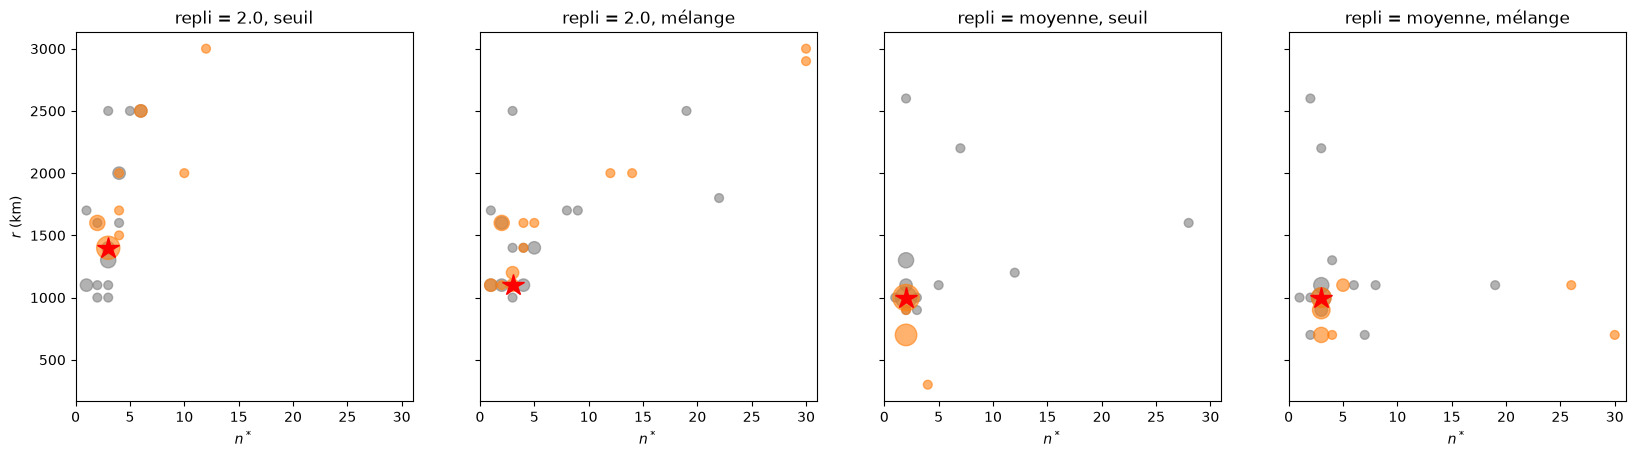

In [37]:
# Graphique : optimum de chaque répétition (gris) et de chaque configuration de 04 (orange) ; taille = nombre de fois ; étoile = optimum global
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharey=True)
for ax, k in zip(axes, recherche):
    for points, couleur in [(optimums_rep[k], "grey"), (optimums_configs[k], "tab:orange")]:
        compte = points.value_counts()
        ax.scatter([n for r, n in compte.index], [r for r, n in compte.index], s=40 * compte.values, color=couleur, alpha=0.6)
    r, n = optimum_de(recherche[k]); ax.plot(n, r, "r*", ms=16)
    ax.set_title(f"repli = {k[0]}, {k[1]}"); ax.set_xlabel("$n^*$"); ax.set_xlim(0, 31)
axes[0].set_ylabel("$r$ (km)")
plt.show()

In [38]:
# Optimum (r, n*) de chaque configuration de 04, pour chaque surface
pd.DataFrame({f"repli {p}, {f}": s for (p, f), s in optimums_configs.items()})

,"repli 2.0, seuil","repli 2.0, mélange","repli moyenne, seuil","repli moyenne, mélange"
BART_V1,"(1600, 2)","(1600, 2)","(1000, 2)","(1000, 3)"
BART_V2,"(1400, 3)","(1600, 2)","(1000, 2)","(1000, 3)"
CatBoost_V1,"(1700, 4)","(1200, 3)","(700, 2)","(700, 3)"
CatBoost_V2,"(1400, 3)","(1200, 3)","(700, 2)","(700, 4)"
Elastic_Net_V1,"(2000, 4)","(1600, 5)","(1000, 2)","(900, 3)"
Elastic_Net_V2,"(1400, 3)","(1400, 4)","(1000, 2)","(1100, 5)"
Elastic_Net_V2_bride,"(1400, 3)","(1100, 3)","(1000, 2)","(1000, 3)"
GAM_V1,"(1500, 4)","(2000, 14)","(700, 2)","(1100, 5)"
GAM_V2,"(1400, 3)","(2000, 12)","(1000, 2)","(900, 3)"
GP_V1,"(3000, 12)","(3000, 30)","(300, 4)","(700, 30)"


**Constat :**
- **Avec repli sur la moyenne, l'optimum est très stable.** En mélange, l'écart interquartile entre répétitions est de 100 km pour $r$ et de 0.25 pour $n^*$. D'une configuration à l'autre, il est de 300 km et 1. **9 des 17 configurations tombent sur $r$ entre 900 et 1 100 km et $n^* = 3$** : Elastic Net V1 et V2 bridé, BART V1 et V2, SVR V1 et V2, GAM V2, Random Forest V1 et V2. Elastic Net V2 non bridé et GAM V1 en sont proches (1 100 km, $n^* = 5$). Les vraies exceptions sont les configurations qui font moins bien que la simple moyenne en 04 : XGBoost et CatBoost (700 km), et surtout le GP ($n^*$ de 26 à 30), pour lequel la règle revient presque partout à la constante.
- **Avec repli sur 2.0, l'optimum est dispersé** : écart interquartile de 600 à 900 km pour $r$ entre répétitions, de 500 à 600 km entre configurations ; optimums de (1 100 km, 1) à (3 000 km, 30).
- **Explication.** Avec repli sur 2.0, la perte mêle deux choses : l'information locale du modèle, et l'écart entre le niveau de nos sites (2.51) et 2.0. Cet écart de niveau change avec le découpage (quels sites sont en test) et avec le modèle (chacun a son propre niveau moyen). Avec repli sur la moyenne, il ne reste que l'information locale, qui est une propriété des **données** : la même pour tous les modèles raisonnables.
- **La forme compte aussi** : avec repli sur la moyenne, l'optimum du mélange est plus stable que celui du seuil (écart interquartile entre répétitions : 100 contre 300 km pour $r$, 0.25 contre 1 pour $n^*$).

### Étape 4 — Choix de la perte

**Objectif :** choisir laquelle des deux pertes fixe $r$ et $n^*$.

**Raisonnement :** trois critères, tous vérifiés ci-dessus.
1. **Ce que mesure la perte.** La confiance doit répondre à une question : *le modèle apporte-t-il ici une information locale ?* La perte avec repli sur la moyenne mesure exactement cela. La perte avec repli sur 2.0 récompense en plus le niveau de nos sites (2.51 contre 2.0), qui ne se transpose pas aux régions sans site (04, partie A). Or ce sont justement les régions où la règle revient à la valeur de repli.
2. **Stabilité entre répétitions** (étape 3) : écart interquartile de $r$ de 100 km, contre 600 km avec repli sur 2.0 (mélange).
3. **Indépendance vis-à-vis du modèle** (étape 3) : 9 configurations sur 17 donnent le même optimum avec repli sur la moyenne ; avec repli sur 2.0, les optimums sont dispersés.

**Décision : la perte retenue utilise le repli sur la moyenne d'entraînement pendant l'évaluation.**

Sur la carte, la valeur de repli reste 2.0. Les deux questions sont séparées : le réglage $(r, n^*)$ dit **où** le modèle est fiable ; la valeur de repli dit **quoi mettre ailleurs**, et elle a été fixée par l'équipe.

La partie D (étape 3) compare à nouveau les deux pertes, sans optimisme (validation croisée imbriquée), et mesure ce que coûte ce choix sur nos sites quand la règle est évaluée avec le repli sur 2.0, comme sur la carte.

In [39]:
# Perte retenue (cf. raisonnement ci-dessus) : repli sur la moyenne d'entraînement pendant l'évaluation
PERTE = "moyenne"

### Étape 5 — Seuil ou mélange : ce que dit la validation croisée

**Objectif :** comparer les deux formes de la règle, chacune à son optimum, avec la perte retenue.

**Raisonnement :** écart apparié entre le meilleur seuil et le meilleur mélange, avec son erreur standard (Nadeau et Bengio). Si l'écart reste sous une erreur standard, la validation croisée ne départage pas les deux formes, et le choix doit reposer sur d'autres critères (partie C).

In [40]:
# Meilleur seuil contre meilleur mélange, pour la perte retenue (écart apparié : seuil − mélange)
comparer(scores_de(recherche[(PERTE, "seuil")], optimum_de(recherche[(PERTE, "seuil")])),
         scores_de(recherche[(PERTE, "mélange")], optimum_de(recherche[(PERTE, "mélange")]))).round(3)

écart                       -0.003
erreur standard              0.013
plis où a fait mieux (%)    51.000
dtype: float64

**Constat :** le meilleur seuil et le meilleur mélange sont **indiscernables** : −0.003 ± 0.013 (le seuil fait mieux dans 51 % des plis). La validation croisée ne départage pas les deux formes. Le seul argument statistique va au mélange : son optimum est plus stable d'une répétition à l'autre (étape 3). Le choix se fait donc sur des critères propres à la carte et à ORCHIDEE (partie C).

## Partie C — Seuil ou mélange : critères propres à la carte et à ORCHIDEE

**Objectif :** départager les deux formes sur ce qui compte pour l'usage final : une carte de Q10 lue par ORCHIDEE, et appelée à être recalculée quand de nouveaux sites seront ajoutés.

**Raisonnement :** deux critères mesurables sur la carte mondiale, chaque forme étant prise à son propre optimum :
1. **Sauts entre cellules voisines.** Avec le seuil, Q10 passe brutalement de 2.0 à la valeur du modèle au bord de chaque cercle de rayon $r$. Ce saut n'a aucun sens physique ; ORCHIDEE en hériterait sous la forme de gradients artificiels de décomposition du carbone du sol. On mesure l'écart de Q10 entre cellules voisines **dont la confiance diffère** : ce sont les sauts créés par la règle elle-même, et non ceux, réels ou non, du modèle.
2. **Sensibilité à un site.** Nos données vont augmenter un peu. On retire chaque site, l'un après l'autre (c'est l'opération inverse d'un ajout), et on mesure le changement de la carte. Le modèle n'est pas réentraîné : on isole ainsi l'effet de la règle de confiance. Une règle robuste ne doit pas changer brutalement la carte quand on ajoute ou retire un seul site.

In [41]:
# Grille mondiale de 0.5° (cf. 06) : variables de chaque cellule, index = ligne × 720 + colonne
grille = pd.read_csv("../data/grille_05deg.csv.gz", index_col="cellule")

In [42]:
# Candidats sur la grille, au même format que X (mêmes colonnes, dans le même ordre)
X_grille = grille[candidats].join(pd.get_dummies(grille.typologie, dtype=float)).reindex(columns=X.columns, fill_value=0.0)

In [43]:
# Elastic Net V2 entraîné sur les 131 sites (sélection LASSO d'abord), comme pour la carte de 04
modele, colonnes = M.ajuster_final(lambda p: M.elastic_net(), X, v4.log_Q10, v4.bloc)

In [44]:
# Q10 prédit par le modèle seul sur chaque cellule, variables bridées à la plage des sites (cf. 04, partie C, étape 4)
q_modele = pd.Series(np.exp(modele.predict(X_grille.clip(X.min(), X.max(), axis=1)[colonnes])), index=grille.index)

In [45]:
# Distances (km) de chaque cellule à chaque site (tableau 64 745 × 131)
D_grille = distance_km(grille.lat.values[:, None], grille.lon.values[:, None], v4.lat.values, v4.lon.values)

In [46]:
# Fonction : confiance de chaque cellule pour une forme et un réglage (r, n*), avec les seuls sites indiqués (par défaut : tous)
def confiance_grille(forme, r, n_etoile, sites=slice(None)):
    return pd.Series(confiance((D_grille[:, sites] < r).sum(axis=1), n_etoile, forme), index=grille.index)

In [47]:
# Confiance et carte de chaque forme, à son optimum pour la perte retenue (repli : 2.0)
confiances = {f: confiance_grille(f, *optimum_de(recherche[(PERTE, f)])) for f in FORMES}
cartes = {f: regle(q_modele, Q10_REFERENCE, c) for f, c in confiances.items()}

In [48]:
# Fonction : tableau 2D (300 × 720) d'une série indexée par les cellules de la grille, vide ailleurs (comme dans 04)
def carte(serie):
    tableau = np.full(300 * 720, np.nan)
    tableau[serie.index] = serie.values
    return tableau.reshape(300, 720)

### Étape 1 — Sauts entre cellules voisines

In [49]:
# Fonction : écarts absolus de Q10 entre cellules voisines (est-ouest et nord-sud) dont la confiance diffère, c'est-à-dire créés par la règle
def sauts_aux_bords(forme):
    q_2d, c_2d = carte(cartes[forme]), carte(confiances[forme])
    s = np.concatenate([np.abs(np.diff(q_2d, axis=k))[np.diff(c_2d, axis=k) != 0] for k in (0, 1)])
    return pd.Series(s[~np.isnan(s)])

In [50]:
# Sauts créés par la règle : nombre de paires de cellules voisines concernées, médiane, 90e centile et maximum de l'écart de Q10
pd.DataFrame({f: sauts_aux_bords(f).describe(percentiles=[0.5, 0.9])[["count", "50%", "90%", "max"]] for f in FORMES}).T.round(2)

,count,50%,90%,max
seuil,843.0,0.36,1.17,2.40
mélange,2200.0,0.15,0.44,1.94


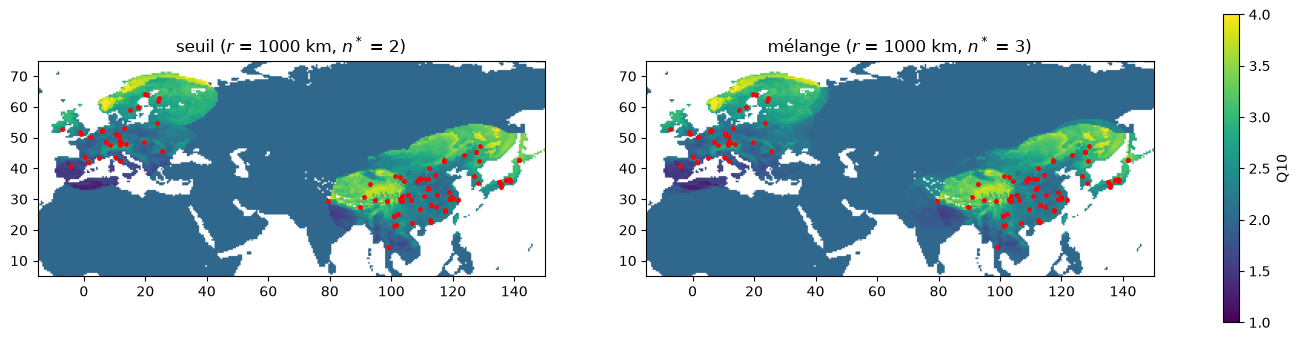

In [51]:
# Graphique : les deux cartes sur l'Eurasie, où le bord des cercles traverse des régions sans site
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, forme in zip(axes, FORMES):
    im = ax.imshow(carte(cartes[forme]), extent=(-180, 180, -60, 90), vmin=1, vmax=4, cmap="viridis")
    ax.scatter(v4.lon, v4.lat, s=6, c="r"); ax.set_xlim(-15, 150); ax.set_ylim(5, 75)
    r, n = optimum_de(recherche[(PERTE, forme)]); ax.set_title(f"{forme} ($r$ = {r} km, $n^*$ = {n})")
fig.colorbar(im, ax=axes, shrink=0.8, label="Q10")
plt.show()

**Constat :**
- **Le mélange divise par plus de deux les sauts créés par la règle** : médiane de 0.15 contre 0.36, 90e centile de 0.44 contre 1.17. Avec le seuil, 10 % des sauts dépassent 1.17, c'est-à-dire un Q10 qui passe par exemple de 2.0 à 3.2 d'une cellule à la voisine, au bord d'un cercle.
- **Les sauts sont plus nombreux avec le mélange** (2 200 paires de cellules contre 843), car la confiance change par paliers de $1/3$, à chaque cercle franchi. Mais ils sont plus petits.
- **Le saut maximal reste élevé dans les deux cas** (1.94 contre 2.40). Il se produit là où plusieurs sites sont presque au même endroit : leurs cercles se confondent, et la confiance passe de 0 à 1 d'un coup, même en mélange.

### Étape 2 — Sensibilité de la carte à un site

In [52]:
# Fonction : changement maximal de la carte d'une forme (|ΔQ10| sur la cellule la plus touchée) quand on retire le site k
def changement(forme, k):
    sites = np.delete(np.arange(len(v4)), k)
    return np.abs(regle(q_modele, Q10_REFERENCE, confiance_grille(forme, *optimum_de(recherche[(PERTE, forme)]), sites)) - cartes[forme]).max()

In [53]:
# Changement maximal de la carte pour chaque site retiré, l'un après l'autre (lignes), et pour chaque forme (colonnes) (≈ 30 s)
sensibilite = pd.DataFrame({f: [changement(f, k) for k in range(len(v4))] for f in FORMES})

In [54]:
# Résumé : distribution, sur les 131 sites retirés, du changement maximal de la carte
sensibilite.describe(percentiles=[0.5, 0.9]).T[["50%", "90%", "max"]].round(2)

,50%,90%,max
seuil,0.00,1.32,1.97
mélange,0.08,0.59,0.84


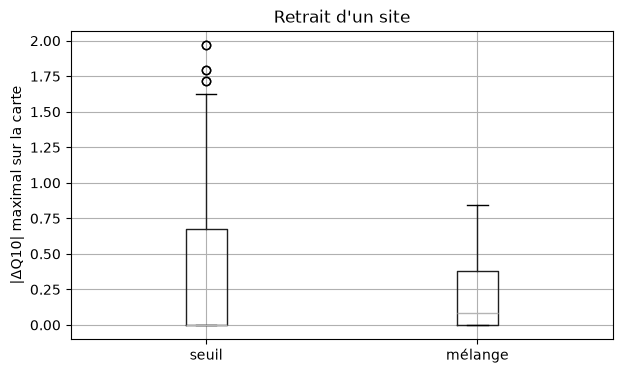

In [55]:
# Graphique : changement maximal de la carte quand on retire un site, pour chaque forme
fig, ax = plt.subplots(figsize=(7, 4))
sensibilite.boxplot(ax=ax)
ax.set_ylabel("|ΔQ10| maximal sur la carte"); ax.set_title("Retrait d'un site")
plt.show()

**Constat :**
- **Avec le seuil, un seul site peut changer brutalement toute une région.** Dans la moitié des cas, retirer un site ne change rien à la carte (médiane 0). Mais dans 10 % des cas, une région entière se déplace de plus de 1.32, et jusqu'à 1.97 : un disque de 1 000 km bascule entre 2.0 et la valeur du modèle.
- **Avec le mélange, les changements sont plus fréquents mais deux fois plus petits** : médiane 0.08, 90e centile 0.59, maximum 0.84. Un site ne déplace la confiance que de $1/n^* = 1/3$ au plus, sauf là où plusieurs sites sont confondus.
- **Conséquence pour la suite du projet** : avec le mélange, chaque nouveau site modifiera la carte progressivement, sans faire basculer brutalement des régions entières d'une version à l'autre de la carte livrée à ORCHIDEE.

**Décision : la règle retenue est le mélange.** Les arguments vont tous dans le même sens :
- les deux formes sont équivalentes en validation croisée (partie B, étape 5) ;
- l'optimum du mélange est plus stable (partie B, étape 3) ;
- ses sauts au bord des cercles sont deux fois plus petits (étape 1) ;
- il est deux fois moins sensible à l'ajout ou au retrait d'un site (ci-dessus).

Le rayon et le nombre de sites retenus sont alors l'optimum de la surface « repli sur la moyenne, mélange ».

In [56]:
# Forme retenue (cf. constat ci-dessus), puis rayon et nombre de sites retenus : l'optimum de la surface correspondante
FORME = "mélange"
R, N_ETOILE = optimum_de(recherche[(PERTE, FORME)])
print(f"Règle retenue : {FORME}, r = {R} km, n* = {N_ETOILE}")

Règle retenue : mélange, r = 1000 km, n* = 3


## Partie D — Robustesse du réglage retenu

### Étape 1 — Profils autour de l'optimum

**Objectif :** montrer, comme pour une recherche sur grille classique, que le réglage retenu minimise la perte, et avec quelle marge.

**Raisonnement :** on fait varier un paramètre à la fois autour de l'optimum : $r$, avec $n^*$ fixé à sa valeur retenue, puis $n^*$, avec $r$ fixé. Pour chaque règle, on trace son **écart apparié de RMSE avec la règle retenue**, avec une erreur standard (Nadeau et Bengio). Un écart positif veut dire « moins bon que la règle retenue » ; une barre qui ne touche pas 0 signale une règle nettement moins bonne. On trace aussi, pour mémoire, les cas limites (modèle seul, moyenne seule).

In [57]:
# Écart apparié de chaque règle de la surface retenue avec la règle retenue, et son erreur standard
retenue = scores_de(recherche[(PERTE, FORME)], (R, N_ETOILE))
ecarts_retenue = pd.DataFrame({rn: comparer(scores_de(recherche[(PERTE, FORME)], rn), retenue) for rn in recherche[(PERTE, FORME)].index}).T

In [58]:
# Écarts des cas limites avec la règle retenue : modèle seul (confiance 1 partout) et moyenne seule (confiance 0 partout)
limites = {"modèle seul": comparer(scores_modele, retenue), "moyenne seule": comparer(scores_moyenne, retenue)}
pd.DataFrame(limites).T.round(3)

,écart,erreur standard,plis où a fait mieux (%)
modèle seul,0.028,0.029,37.0
moyenne seule,0.058,0.039,16.0


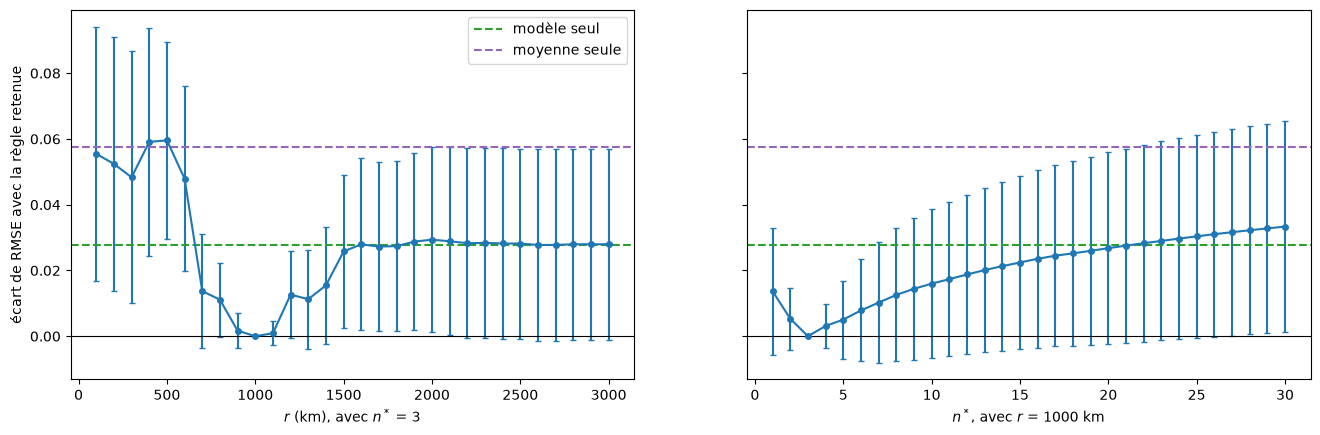

In [59]:
# Graphique : profils de l'écart à la règle retenue (± une erreur standard), selon r puis selon n*
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
for ax, (profil, nom) in zip(axes, [(ecarts_retenue.xs(N_ETOILE, level=1), f"$r$ (km), avec $n^*$ = {N_ETOILE}"), (ecarts_retenue.xs(R, level=0), f"$n^*$, avec $r$ = {R} km")]):
    ax.errorbar(profil.index, profil["écart"], yerr=profil["erreur standard"], marker="o", ms=4, capsize=2)
    for (cas_limite, e), couleur in zip(limites.items(), ["tab:green", "tab:purple"]):
        ax.axhline(e["écart"], color=couleur, ls="--", label=cas_limite)
    ax.axhline(0, color="k", lw=0.8); ax.set_xlabel(nom)
axes[0].set_ylabel("écart de RMSE avec la règle retenue"); axes[0].legend()
plt.show()

**Constat :**
- **Le profil selon $r$ a une forme nette, en U.** Jusqu'à 600 km, la règle est nettement moins bonne (+0.05 à +0.06 ; les barres ne touchent pas 0). Entre 900 et 1 100 km, elle est au plus bas. Au-delà de 1 500 km, l'écart remonte à +0.028 et rejoint celui du modèle seul : avec un si grand rayon, presque toutes les cellules ont 3 voisins, et la règle fait toujours confiance au modèle.
- **Le profil selon $n^*$ est plus plat.** Le minimum est à 3. Avec $n^* = 1$, l'écart est de +0.014 ± 0.019 ; au-delà de 3, il croît lentement, jusqu'à +0.033 ± 0.032 pour $n^* = 30$.
- **Cas limites** : le modèle seul fait +0.028 ± 0.029 de plus que la règle retenue (moins bon dans 63 % des plis), et la moyenne seule +0.058 ± 0.039. Comme le montrait l'étape 2 de la partie B, la marge sur les réglages voisins reste sous une erreur standard. Ce qui est solide, c'est **l'emplacement** du minimum, pas l'ampleur du gain.
- **Le rayon trouvé a un sens physique** : $r \approx 1\,000$ km est la portée du semi-variogramme mesurée indépendamment dans 02 (≈ 1 000 à 1 500 km), c'est-à-dire la distance jusqu'à laquelle les Q10 de deux sites se ressemblent encore. La recherche sur grille retrouve cette valeur sans qu'on la lui impose. La remontée au-delà de 1 500 km correspond au palier du semi-variogramme : plus loin, un site n'apporte plus d'information.
- **Pour ORCHIDEE**, 1 000 km représentent ≈ 18 cellules de 0.5° : la confiance varie lentement à l'échelle de la grille du modèle.

### Étape 2 — L'optimum dépend-il de la quantité de données ?

**Objectif :** nos données vont augmenter un peu. Vérifier que le réglage retenu ne dépend pas du nombre de sites, et qu'il n'y aura donc pas à le refaire à chaque ajout.

**Raisonnement :**
- On ne peut pas simuler des sites qui n'existent pas encore. On fait donc l'inverse : on **retire** une partie des sites (on garde 60, 70, 80 ou 90 % des sites, 5 tirages au hasard par fraction), on refait toute la chaîne (validation croisée spatiale de l'Elastic Net V2 bridé, puis recherche sur grille), et on regarde si l'optimum se déplace.
- Si l'optimum ne bouge pas entre 60 % et 100 % des données, il est peu probable qu'il bouge avec quelques sites de plus.
- 10 répétitions par tirage, au lieu de 20, pour limiter le temps de calcul (≈ 5 min au premier calcul, puis cache).

In [60]:
# Sites gardés dans chaque sous-échantillon : fraction des sites tirée au hasard, 5 tirages par fraction
FRACTIONS, TIRAGES = [0.6, 0.7, 0.8, 0.9], range(5)
gardes = {(f, t): np.sort(np.random.default_rng(t).choice(len(v4), int(round(f * len(v4))), replace=False)) for f in FRACTIONS for t in TIRAGES}

In [61]:
# Découpages spatiaux de chaque sous-échantillon (10 répétitions), exprimés en indices de v4
decoupages_sous = {k: [(s, g[tr], g[te]) for s, tr, te in decoupages_spatiaux(v4.bloc.iloc[g], n_repetitions=10)] for k, g in gardes.items()}

In [62]:
# Prédictions hors échantillon de l'Elastic Net V2 bridé, réentraîné sur chaque sous-échantillon (cache)
oof_sous = {k: evaluer_en_cache(f"../resultats/07/sous_echantillons/{k[0]}_{k[1]}.pkl", predire_en, d, v4.Q10)[1] for k, d in decoupages_sous.items()}

In [63]:
# Optimum (r, n*) de chaque sous-échantillon, avec la perte et la forme retenues
optimums_sous = pd.DataFrame([(f, t, *optimum_de(recherche_grille(oof_sous[(f, t)], d, [D[np.ix_(te, tr)] for _, tr, te in d], FORME, REPLIS[PERTE])))
                              for (f, t), d in decoupages_sous.items()], columns=["fraction", "tirage", "r", "n*"])

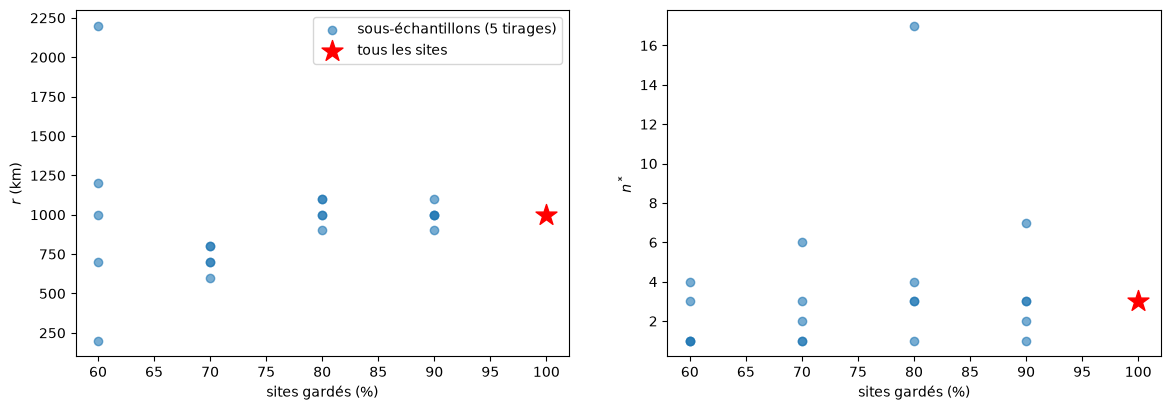

In [64]:
# Graphique : optimum de chaque tirage selon la fraction de sites gardés ; à 100 %, l'optimum retenu
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, colonne, etiquette, retenu in zip(axes, ["r", "n*"], ["$r$ (km)", "$n^*$"], [R, N_ETOILE]):
    ax.scatter(optimums_sous.fraction * 100, optimums_sous[colonne], alpha=0.6, label="sous-échantillons (5 tirages)")
    ax.scatter(100, retenu, marker="*", s=250, color="r", label="tous les sites")
    ax.set_xlabel("sites gardés (%)"); ax.set_ylabel(etiquette)
axes[0].legend()
plt.show()

In [65]:
# Médiane et écart interquartile de r (km) et de n* sur les 5 tirages, pour chaque fraction de sites gardés
optimums_sous.groupby("fraction")[["r", "n*"]].agg(["median", iqr])

r            n*     
          median    iqr median  iqr
fraction                           
0.6       1000.0  500.0    1.0  2.0
0.7        700.0  100.0    2.0  2.0
0.8       1000.0  100.0    3.0  1.0
0.9       1000.0    0.0    3.0  1.0

**Constat :**
- **À 80 % et 90 % des sites, l'optimum ne bouge pas** : médiane de $r$ : 1 000 km (écart interquartile de 100 km, puis 0) ; médiane de $n^*$ : 3 (écart interquartile de 1).
- **En dessous, il devient instable** : $r$ va de 200 à 2 200 km avec 60 % des sites, et tombe à 700 km avec 70 % ; $n^*$ descend à 1 ou 2. Avec moins de ≈ 100 sites, il y a trop peu de contrastes entre sites isolés et sites entourés pour situer l'optimum.
- **L'optimum converge donc quand les données augmentent**, et il est stable à partir de ≈ 105 sites. Quelques sites de plus ne devraient pas le déplacer. Il faudrait refaire la recherche si les nouveaux sites changent la géographie des données (par exemple, de nombreux sites tropicaux), car l'optimum décrit la structure spatiale des sites actuels.
- **Les unités choisies aident** : $r$ est une distance physique, et $n^*$ un nombre absolu de sites. Quand on ajoute des sites, la règle étend d'elle-même la zone où le modèle est utilisé, sans qu'il faille la régler à nouveau.

### Étape 3 — Validation croisée imbriquée : le gain survit-il au choix du réglage ?

**Objectif :** estimer honnêtement ce qu'apporte la règle. L'optimum de la partie B a été choisi sur les mêmes plis que ceux qui mesurent son erreur : son score est donc un peu optimiste.

**Raisonnement :**
- Pour chacun des 100 plis, on choisit $(r, n^*)$ **avec les seuls sites d'entraînement** : validation croisée spatiale interne (5 plis × 4 répétitions), recherche sur grille, optimum. On applique ensuite ce réglage aux sites de test du pli, qui n'ont servi à rien dans ce choix.
- On fait ce choix avec **chacune des deux pertes** de la partie B : c'est la comparaison la plus honnête entre elles, puisque le réglage est choisi sans voir les sites de test.
- On évalue ensuite la règle sur les sites de test avec le repli sur 2.0 (comme sur la carte) et avec le repli sur la moyenne, et on la compare au modèle seul, à 2.0 et à la moyenne, par écarts appariés.
- On regarde aussi les réglages choisis dans les 100 plis : c'est un dernier test de stabilité.
- Calcul : 2 000 ajustements de l'Elastic Net V2 bridé (≈ 10 min au premier calcul, puis cache).

In [66]:
# Découpages internes : pour chaque pli, validation croisée spatiale sur ses seuls sites d'entraînement (5 plis × 4 répétitions)
decoupages_internes = [[(si, tr[tri], tr[tei]) for si, tri, tei in decoupages_spatiaux(v4.bloc.iloc[tr], n_repetitions=4)] for _, tr, _ in decoupages]

In [67]:
# Prédictions hors échantillon internes de chaque pli (cache)
oof_internes = [evaluer_en_cache(f"../resultats/07/imbriquee/pli_{i:03d}.pkl", predire_en, d, v4.Q10)[1] for i, d in enumerate(decoupages_internes)]

In [68]:
# Réglage (r, n*) choisi dans chaque pli sur ses seuls sites d'entraînement, avec chacune des deux pertes (forme retenue)
choix_internes = {perte: pd.DataFrame([optimum_de(recherche_grille(o, d, [D[np.ix_(te, tr)] for _, tr, te in d], FORME, REPLIS[perte])) for o, d in zip(oof_internes, decoupages_internes)],
                                      columns=["r", "n*"]) for perte in REPLIS}

In [69]:
# Réglages les plus fréquents dans les 100 plis, pour chaque perte de sélection
pd.concat({f"choisi avec repli {p}": c.value_counts().head(6).reset_index() for p, c in choix_internes.items()}, axis=1)

choisi avec repli 2.0          choisi avec repli moyenne         
                      r n* count                         r n* count
0                  1600  1     8                      1100  3    15
1                  1600  2     8                      1000  3    12
2                  1100  3     8                       900  3     7
3                  1100  1     5                      1000  1     5
4                  1100  4     4                       700  3     5
5                  2000  8     3                       700  4     3

In [70]:
# Dispersion des réglages choisis dans les 100 plis : écart interquartile de r (km) et de n*
pd.DataFrame({f"choisi avec repli {p}": c.apply(iqr) for p, c in choix_internes.items()}).T

,r,n*
choisi avec repli 2.0,825.0,10.25
choisi avec repli moyenne,200.0,2.00


In [71]:
# RMSE de la règle sur chaque pli, avec le réglage choisi dans le pli : pour chaque perte de sélection et chaque repli d'évaluation (NOMBRES = 1, 2, …, 30)
imbriquee = {(choix, repli): pd.DataFrame({"rmse": [rmse_pli(p, d, oof, r, FORME, REPLIS[repli])[n - 1] for p, d, (r, n) in zip(decoupages, distances, choix_internes[choix].values)]})
             for choix in REPLIS for repli in REPLIS}

In [72]:
# Fonction : résumé d'une règle évaluée sur les 100 plis : RMSE, et écart apparié (± erreur standard) avec chaque référence
references = {"modèle seul": scores_modele, "2.0": scores_deux, "moyenne": scores_moyenne}
def resume_regle(scores):
    ecarts = {nom: comparer(scores, ref) for nom, ref in references.items()}
    return pd.Series({"RMSE": round(scores.rmse.mean(), 3), **{f"vs {nom}": f"{e['écart']:+.3f} ± {e['erreur standard']:.3f}" for nom, e in ecarts.items()}})

In [73]:
# Règle à réglage imbriqué, comparée aux trois références (écart = règle − référence ; négatif = la règle fait mieux)
pd.DataFrame({f"choix avec repli {c} → évaluée avec repli {r}": resume_regle(s) for (c, r), s in imbriquee.items()}).T

,RMSE,vs modèle seul,vs 2.0,vs moyenne
choix avec repli 2.0 → évaluée avec repli 2.0,0.953,+0.004 ± 0.019,-0.130 ± 0.043,-0.026 ± 0.048
choix avec repli 2.0 → évaluée avec repli moyenne,0.949,-0.001 ± 0.027,-0.134 ± 0.044,-0.031 ± 0.043
choix avec repli moyenne → évaluée avec repli 2.0,0.979,+0.029 ± 0.035,-0.104 ± 0.043,-0.001 ± 0.050
choix avec repli moyenne → évaluée avec repli moyenne,0.955,+0.005 ± 0.035,-0.128 ± 0.047,-0.025 ± 0.036


**Constat :**
- **Stabilité** : avec la perte « repli sur la moyenne », les réglages choisis dans les plis se concentrent autour de (900 à 1 100 km, $n^* = 3$) ; écart interquartile de 200 km pour $r$ et de 2 pour $n^*$. Avec la perte « repli sur 2.0 », ils sont dispersés (825 km et 10) ; les plus fréquents vont de (1 100 km, 1) à (2 000 km, 8). Cela confirme l'étape 4 de la partie B, cette fois sans optimisme.
- **Toutes les variantes battent 2.0 nettement** : de −0.104 à −0.134, à plus de deux erreurs standard.
- **Aucune variante ne fait mieux que le modèle seul sur nos sites** : les écarts vont de −0.001 à +0.029, tous sous une erreur standard.
- **La version livrée** (réglage choisi avec repli sur la moyenne, carte avec repli sur 2.0) fait **0.979**, soit **+0.029 ± 0.035** de plus que le modèle seul, et autant que la moyenne (−0.001 ± 0.050). La même règle évaluée avec le repli sur la moyenne ne coûte rien (+0.005). **Ce coût vient donc entièrement de l'écart entre 2.0 et le niveau de nos sites** : nos sites de test peu entourés ont un Q10 d'environ 2.5, et revenir à 2.0, même en partie, les pénalise.
- **Choisir le réglage avec la perte « repli sur 2.0 » réduit ce coût sur nos sites** (+0.004 ± 0.019), mais par un mécanisme qu'on ne veut pas transposer à la carte : les réglages choisis sont plus larges (souvent $r = 1\,600$ km avec $n^* = 1$ ou 2), ce qui étend le modèle plus loin des sites, parce que la perte récompense le niveau de nos sites. C'est le biais identifié dans la partie B (étape 4).
- **Lecture d'ensemble** : sur nos sites, la règle de confiance n'améliore pas la prédiction, et ce n'est pas son rôle. Elle empêche d'extrapoler là où le modèle n'a pas d'information locale (partie A). La validation croisée ne peut pas mesurer ce bénéfice, car tous nos sites de test viennent des mêmes régions. **Le prix de cette prudence, mesuré sur nos sites, est d'environ 0.03 de RMSE**, sous une erreur standard.

## Partie E — Carte mondiale

### Étape 1 — Confiance et Q10 sur la grille

**Objectif :** appliquer la règle retenue à la grille mondiale et décrire la carte obtenue.

**Raisonnement :** la confiance de chaque cellule est calculée avec les 131 sites, le modèle est l'Elastic Net V2 bridé entraîné sur les 131 sites (partie C), et la valeur de repli est 2.0. On résume la carte par la part des terres à chaque niveau de confiance et par le Q10 moyen (pondéré par l'aire), en particulier dans les régions froides (MAT inférieure à celle de tous nos sites), où les modèles divergeaient (04, partie C).

In [74]:
# Confiance de chaque cellule et Q10 de la carte finale : ceux de la forme retenue, à son optimum (partie C)
c_grille, q_carte = confiances[FORME], cartes[FORME]

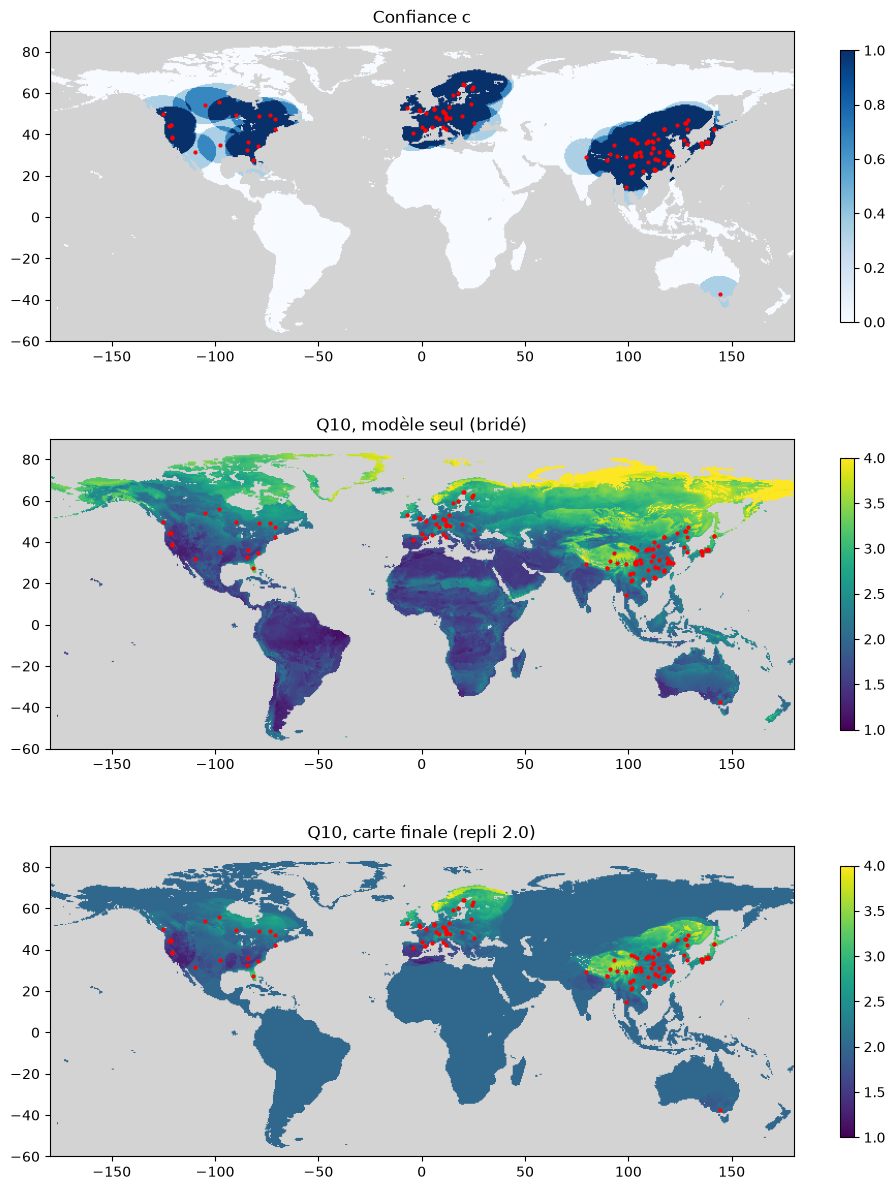

In [75]:
# Graphique : confiance, Q10 du modèle seul et Q10 de la carte finale ; points rouges = sites, mer en gris
fig, axes = plt.subplots(3, 1, figsize=(12, 15))
for ax, (titre, serie, cmap, vmin, vmax) in zip(axes, [("Confiance c", c_grille, "Blues", 0, 1), ("Q10, modèle seul (bridé)", q_modele, "viridis", 1, 4), ("Q10, carte finale (repli 2.0)", q_carte, "viridis", 1, 4)]):
    im = ax.imshow(carte(serie), extent=(-180, 180, -60, 90), cmap=cmap, vmin=vmin, vmax=vmax)
    ax.scatter(v4.lon, v4.lat, s=4, c="r"); ax.set_facecolor("lightgrey"); ax.set_title(titre); fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

In [76]:
# Part des terres (%) selon la confiance : 0 (repli), entre 0 et 1 (mélange), 1 (modèle seul)
niveau = pd.cut(c_grille, [-0.01, 0, 0.999, 1], labels=["c = 0 (2.0)", "0 < c < 1", "c = 1 (modèle)"])
grille.aire.groupby(niveau, observed=False).sum().div(grille.aire.sum()).mul(100).round(1)

c = 0 (2.0)       70.3
0 < c < 1          9.7
c = 1 (modèle)    20.0
Name: aire, dtype: float64

In [77]:
# Q10 moyen (pondéré par l'aire) : sur toutes les terres et sur les régions plus froides que tous nos sites
froid = grille.MAT_public < v4.MAT_public.min()
moyenne_ponderee = lambda s, masque: np.average(s[masque], weights=grille.aire[masque])
pd.DataFrame({nom: {"terres": moyenne_ponderee(s, grille.aire > 0), "régions froides": moyenne_ponderee(s, froid)} for nom, s in {"modèle seul": q_modele, "carte finale": q_carte}.items()}).T.round(2)

,terres,régions froides
modèle seul,2.16,3.4
carte finale,2.08,2.1


**Constat :**
- **La carte ne s'écarte de 2.0 que là où nous avons des données** :
  - **20 % des terres** ($c = 1$) reçoivent le modèle : Europe, Chine et Asie de l'Est, Amérique du Nord tempérée ;
  - **9.7 %** ($0 < c < 1$) reçoivent un mélange : bords de ces régions, et le sud-est de l'Australie (un seul site) ;
  - **70.3 %** gardent la valeur actuelle d'ORCHIDEE, 2.0.
- **Les contrastes viennent des régions mesurées** : Q10 élevé (≈ 3 à 3.5) en Scandinavie et dans le nord-est de la Chine, bas (≈ 1.5) autour de la Méditerranée.
- **Q10 moyen des terres : 2.08**, contre 2.16 pour le modèle seul. La carte reste très proche de la valeur actuelle en moyenne ; son apport est la répartition spatiale, là où elle est étayée.
- **Les régions froides passent de 3.4 à 2.1** (la quasi-totalité est à $c = 0$). Le désaccord entre l'Elastic Net et le BART dans ces régions (3.4 contre 2.9, cf. 04) disparaît de la carte. Mais le signal commun à tous les modèles disparaît aussi : tous y prédisent un Q10 supérieur à 2.8, dans des régions clés pour le carbone du sol (permafrost). **C'est une conséquence assumée du repli sur 2.0, à discuter avec B. Guenet.**

### Étape 2 — Faut-il aussi exiger l'aire d'applicabilité ?

**Objectif :** décider si la confiance doit aussi être mise à 0 hors de l'aire d'applicabilité (04, partie C), c'est-à-dire là où la **combinaison** des variables d'une cellule n'a pas d'équivalent parmi nos sites, même si des sites sont proches.

**Raisonnement :**
- Pour que la validation croisée puisse trancher, il faut qu'assez de sites de test soient hors de l'aire d'applicabilité **de leur pli** (calculée avec les seuls sites d'entraînement, même recette que 04). On mesure d'abord cette part.
- On mesure ensuite ce que cela changerait sur la carte : la part des terres qui ont une confiance positive tout en étant hors de l'aire.

In [78]:
# Imports : distances dans l'espace des variables, groupes de zones, sélection LASSO du protocole
from scipy.spatial.distance import cdist, pdist
from src.protocole import lasso_spatial

In [79]:
# Fonction : aire d'applicabilité définie par les sites tr (Meyer et Pebesma, 2021 ; même recette que 04, partie C) ; True = dans l'aire
def aire_applicabilite(tr, X_cibles):
    retenues = X.columns[lasso_spatial(X.iloc[tr], v4.log_Q10.iloc[tr], v4.bloc.iloc[tr])[-1].coef_ != 0]
    if len(retenues) == 0:  # modèle constant : aucune extrapolation possible dans l'espace des variables
        return np.ones(len(X_cibles), dtype=bool)
    moyenne, ecart_type = X[retenues].iloc[tr].mean(), X[retenues].iloc[tr].std()
    Z, Z_cibles = ((X[retenues].iloc[tr] - moyenne) / ecart_type).values, ((X_cibles[retenues] - moyenne) / ecart_type).values
    d_moyenne, di = pdist(Z).mean(), np.empty(len(tr))
    for _, a, b in decoupages_spatiaux(v4.bloc.iloc[tr], n_repetitions=1):
        di[b] = cdist(Z[b], Z[a]).min(axis=1) / d_moyenne
    q1, q3 = np.percentile(di, [25, 75])
    return cdist(Z_cibles, Z).min(axis=1) / d_moyenne <= q3 + 1.5 * (q3 - q1)

In [80]:
# Part des sites de test hors de l'aire d'applicabilité de leur pli, sur les 100 plis (≈ 20 s)
dans_aire_tests = np.concatenate([aire_applicabilite(tr, X.iloc[te]) for _, tr, te in decoupages])
print(f"{1 - dans_aire_tests.mean():.1%} des cas de test sont hors de l'aire d'applicabilité de leur pli")

4.0% des cas de test sont hors de l'aire d'applicabilité de leur pli


In [81]:
# Aire d'applicabilité sur la grille, avec les 131 sites
dans_aire = pd.Series(aire_applicabilite(np.arange(len(v4)), X_grille), index=grille.index)

In [82]:
# Part des terres (%) selon la confiance et l'aire d'applicabilité
pd.crosstab(niveau, dans_aire.map({True: "dans l'aire", False: "hors de l'aire"}), values=grille.aire, aggfunc="sum", normalize="all",
            rownames=["confiance"], colnames=["aire d'applicabilité"]).mul(100).round(1)

aire d'applicabilité,dans l'aire,hors de l'aire
confiance,,
c = 0 (2.0),11.7,58.5
0 < c < 1,6.1,3.6
c = 1 (modèle),17.8,2.2


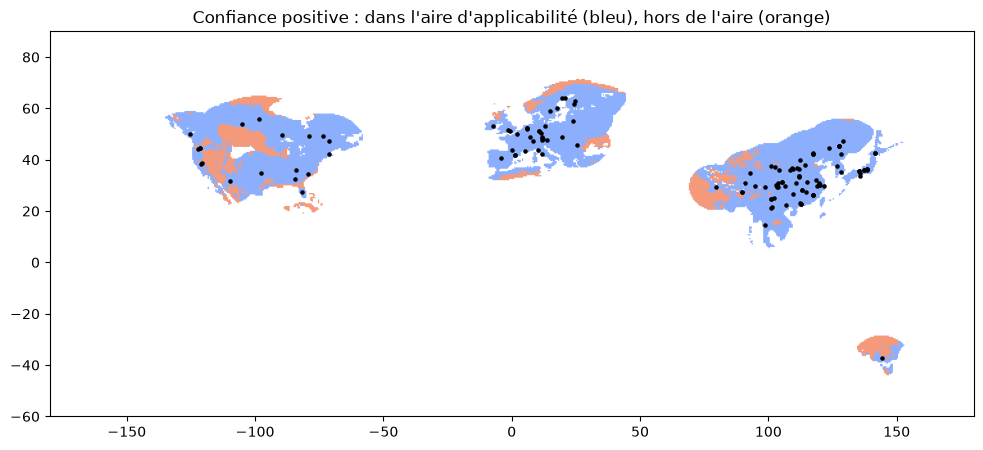

In [83]:
# Graphique : cellules à confiance positive hors de l'aire d'applicabilité (orange), dans l'aire (bleu) ; points noirs = sites
zone = pd.Series(np.where(c_grille == 0, np.nan, np.where(dans_aire, 1.0, 0.0)), index=grille.index)
plt.figure(figsize=(12, 5))
plt.imshow(carte(zone), extent=(-180, 180, -60, 90), cmap="coolwarm_r", vmin=-0.5, vmax=1.5)
plt.scatter(v4.lon, v4.lat, s=5, c="k"); plt.title("Confiance positive : dans l'aire d'applicabilité (bleu), hors de l'aire (orange)")
plt.show()

**Constat :**
- **La validation croisée ne peut pas trancher** : seuls 4.0 % des cas de test sont hors de l'aire d'applicabilité de leur pli. C'est trop peu pour mesurer l'effet de l'aire sur la perte. Ce n'est pas un choix de valeur qu'une recherche sur grille peut fixer : c'est une **décision de prudence**.
- **Effet sur la carte** : 5.8 % des terres ont une confiance positive tout en étant hors de l'aire (3.6 % en mélange, 2.2 % avec $c = 1$). Ce sont surtout le plateau tibétain, le nord du Canada et de la Scandinavie, l'intérieur de l'ouest des États-Unis, et des franges en Afrique du Nord et au Mexique : des régions où un site est proche, mais où le climat ou le sol n'a pas d'équivalent parmi nos sites.
- **Proposition, à valider** : mettre $c = 0$ hors de l'aire d'applicabilité. Elle va dans le sens de la méthode (n'utiliser le modèle que là où il interpole, dans l'espace géographique **et** dans l'espace des variables), et touche peu de surface (5.8 %). Contrepartie : un second critère, dont le seuil (la règle de Meyer et Pebesma) ne peut pas être réglé sur nos données. **Elle n'est pas appliquée dans ce premier jet.**

## Conclusion (premier jet)

**Règle proposée :**

$$c(x) = \min\big(1,\ n_{1000}(x)/3\big), \qquad \log Q_{10}(x) = c(x)\,\log \hat{f}(x) + \big(1 - c(x)\big)\,\log 2.0,$$

avec $\hat{f}$ l'Elastic Net V2 bridé.

**Comment chaque valeur a été choisie :**

| Valeur | Choisie par | Vérifications |
|---|---|---|
| $r = 1\,000$ km | minimum de la surface de perte (repli sur la moyenne, mélange) | stable entre répétitions (écart interquartile de 100 km), pour 9 configurations sur 17, sur les sous-échantillons d'au moins 80 % des sites, dans les choix de la validation croisée imbriquée ; égal à la portée du semi-variogramme (02) |
| $n^* = 3$ | idem | mêmes vérifications ; partie A : un seul voisin ne suffit pas, le modèle apporte une information locale à partir de deux |
| mélange | validation croisée : équivalent au seuil (−0.003 ± 0.013) | optimum plus stable ; sauts au bord des cercles divisés par 2.4 ; sensibilité à un site divisée par 2 |
| perte « repli sur la moyenne » | ne récompense que l'information locale, pas le niveau de nos sites | optimum stable et indépendant du modèle ; coût sur nos sites mesuré (partie D, étape 3) |
| repli = 2.0 | décision de l'équipe (valeur actuelle d'ORCHIDEE) | — |

**Ce que la méthode apporte, et ce qu'elle n'apporte pas :**
- Elle **bat toujours 2.0 nettement** en validation croisée imbriquée : −0.104 ± 0.043 (mieux dans plus de 90 % des plis).
- Elle **n'améliore pas la prédiction sur nos sites** : 0.979 contre 0.950 pour le modèle seul (+0.029 ± 0.035). Ce coût, sous une erreur standard, vient de l'écart entre 2.0 et le niveau de nos sites (2.51). C'est le prix de la prudence.
- Elle **évite d'extrapoler sur 70 % des terres**, où, d'après nos propres données (partie A), le modèle ne fait pas mieux que 2.0 sans site voisin. Ce bénéfice ne peut pas être mesuré par validation croisée, puisque nos sites ne couvrent pas ces régions.

**Décisions à valider par l'équipe :**
1. **La perte de sélection « repli sur la moyenne »**, avec son coût d'environ 0.03 sur nos sites. L'alternative, la perte « repli sur 2.0 », coûte moins sur nos sites (+0.004), mais donne des réglages instables, qui étendent le modèle plus loin des sites.
2. **Le mélange** plutôt que le seuil.
3. **L'aire d'applicabilité** : mettre $c = 0$ hors de l'aire (5.8 % des terres) ?
4. **Les régions froides passent à 2.0** (2.1 en moyenne), alors que tous les modèles y prédisent plus de 2.8 : à discuter avec B. Guenet.

**Limites et pistes :**
- Avec 131 sites, l'emplacement de l'optimum est stable, mais sa marge sur les réglages voisins reste sous une erreur standard.
- Le modèle (Elastic Net V2 bridé) n'est pas encore validé ; le réglage en dépend peu (partie B, étape 3).
- Tous les sites comptent autant, qu'ils soient à 50 km ou à 990 km, et des sites très proches d'une même étude comptent plusieurs fois (d'où les plus grands sauts, partie C). Deux raffinements possibles : une pondération par la distance (un paramètre de plus à régler), ou compter les études plutôt que les sites.
- Prochaine étape, après validation : l'export NetCDF pour ORCHIDEE, avec deux couches (Q10 et confiance $c$).